In [1]:
import os
import shutil
import random
from pathlib import Path
from collections import Counter

from PIL import Image, ImageEnhance, ImageOps, ImageFilter
from tqdm import tqdm

In [17]:
from pathlib import Path

SOURCE_TRAIN_DIR = Path("../data/processed/train")
BALANCED_TRAIN_DIR = Path("../data/balanced/train")

CLASSES = ["real", "deepfake", "edited", "ai_generated"]
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".webp"}

In [18]:
def get_image_files(folder):
    return [p for p in folder.iterdir() if p.suffix.lower() in IMAGE_EXTS and p.is_file()]

def count_images_by_class(base_dir, classes):
    counts = {}
    for cls in classes:
        cls_dir = base_dir / cls
        counts[cls] = len(get_image_files(cls_dir)) if cls_dir.exists() else 0
    return counts

original_counts = count_images_by_class(SOURCE_TRAIN_DIR, CLASSES)
print("Original train class counts:")
for cls, count in original_counts.items():
    print(f"{cls}: {count}")

Original train class counts:
real: 7099
deepfake: 7375
edited: 174
ai_generated: 109


In [19]:
def augment_image(img):
    aug_type = random.choice([
        "flip",
        "rotate",
        "brightness",
        "contrast",
        "sharpness",
        "color",
        "blur",
        "autocontrast"
    ])

    if aug_type == "flip":
        img = ImageOps.mirror(img)

    elif aug_type == "rotate":
        angle = random.choice([-15, -10, -5, 5, 10, 15])
        img = img.rotate(angle)

    elif aug_type == "brightness":
        factor = random.uniform(0.8, 1.2)
        img = ImageEnhance.Brightness(img).enhance(factor)

    elif aug_type == "contrast":
        factor = random.uniform(0.8, 1.2)
        img = ImageEnhance.Contrast(img).enhance(factor)

    elif aug_type == "sharpness":
        factor = random.uniform(0.8, 1.5)
        img = ImageEnhance.Sharpness(img).enhance(factor)

    elif aug_type == "color":
        factor = random.uniform(0.8, 1.2)
        img = ImageEnhance.Color(img).enhance(factor)

    elif aug_type == "blur":
        img = img.filter(ImageFilter.GaussianBlur(radius=random.uniform(0.2, 1.0)))

    elif aug_type == "autocontrast":
        img = ImageOps.autocontrast(img)

    return img

In [20]:
def create_balanced_dataset_with_augmentation(
    source_dir,
    output_dir,
    classes,
    target_count=500,
    seed=42
):
    random.seed(seed)

    source_dir = Path(source_dir)
    output_dir = Path(output_dir)

    # Remove old balanced folder
    if output_dir.exists():
        shutil.rmtree(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    class_to_images = {}
    class_counts = {}

    for cls in classes:
        cls_dir = source_dir / cls
        images = get_image_files(cls_dir)
        class_to_images[cls] = images
        class_counts[cls] = len(images)

    print("Source counts:")
    for cls, count in class_counts.items():
        print(f"{cls}: {count}")

    print(f"\nTarget count per class: {target_count}\n")

    for cls in classes:
        src_images = class_to_images[cls]
        out_cls_dir = output_dir / cls
        out_cls_dir.mkdir(parents=True, exist_ok=True)

        if len(src_images) == 0:
            print(f"Skipping {cls} (no images)")
            continue

        # 🔽 Downsample if too many images
        if len(src_images) > target_count:
            selected_images = random.sample(src_images, target_count)
        else:
            selected_images = src_images

        # Copy selected images
        for img_path in selected_images:
            shutil.copy(img_path, out_cls_dir / img_path.name)

        current_count = len(selected_images)
        needed = target_count - current_count

        # 🔼 Augment if too few images
        if needed > 0:
            for i in tqdm(range(needed), desc=f"Augmenting {cls}"):
                chosen_img_path = random.choice(selected_images)

                try:
                    with Image.open(chosen_img_path).convert("RGB") as img:
                        aug_img = augment_image(img)

                        new_name = f"{chosen_img_path.stem}_aug_{i}.jpg"
                        save_path = out_cls_dir / new_name
                        aug_img.save(save_path, quality=95)

                except Exception as e:
                    print(f"Error processing {chosen_img_path}: {e}")

        print(f"{cls}: {len(src_images)} -> {target_count}")

    print("\n✅ Balanced dataset created at:", output_dir)

In [21]:
create_balanced_dataset_with_augmentation(
    source_dir=SOURCE_TRAIN_DIR,
    output_dir=BALANCED_TRAIN_DIR,
    classes=CLASSES,
    target_count=400,   
    seed=42
)

Source counts:
real: 7099
deepfake: 7375
edited: 174
ai_generated: 109

Target count per class: 400

real: 7099 -> 400
deepfake: 7375 -> 400


Augmenting edited: 100%|██████████| 226/226 [00:03<00:00, 65.45it/s]


edited: 174 -> 400


Augmenting ai_generated: 100%|██████████| 291/291 [00:07<00:00, 40.29it/s]

ai_generated: 109 -> 400

✅ Balanced dataset created at: ..\data\balanced\train


In [23]:
balanced_counts = count_images_by_class(BALANCED_TRAIN_DIR, CLASSES)

print("Balanced train class counts:")
for cls, count in balanced_counts.items():
    print(f"{cls}: {count}")

Balanced train class counts:
real: 400
deepfake: 400
edited: 400
ai_generated: 400


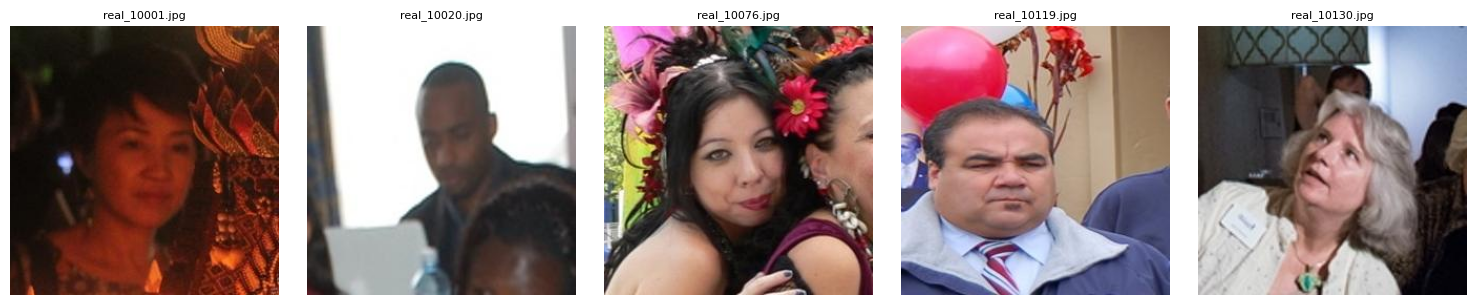

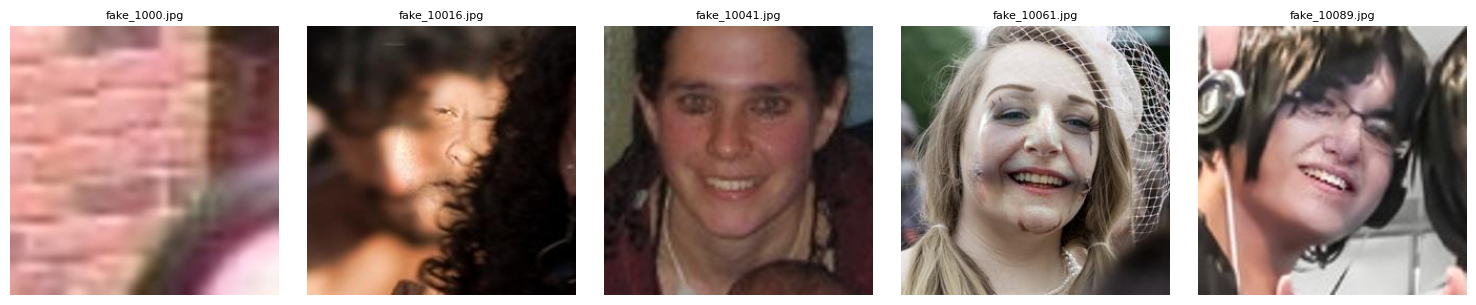

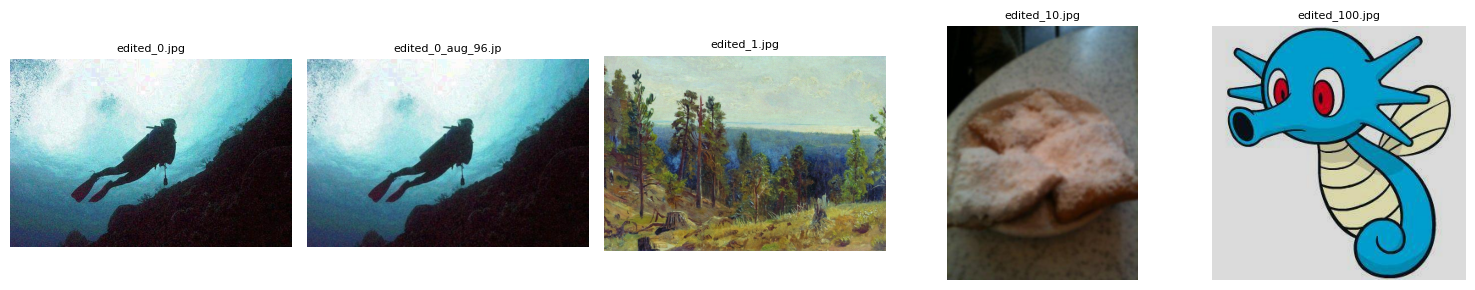

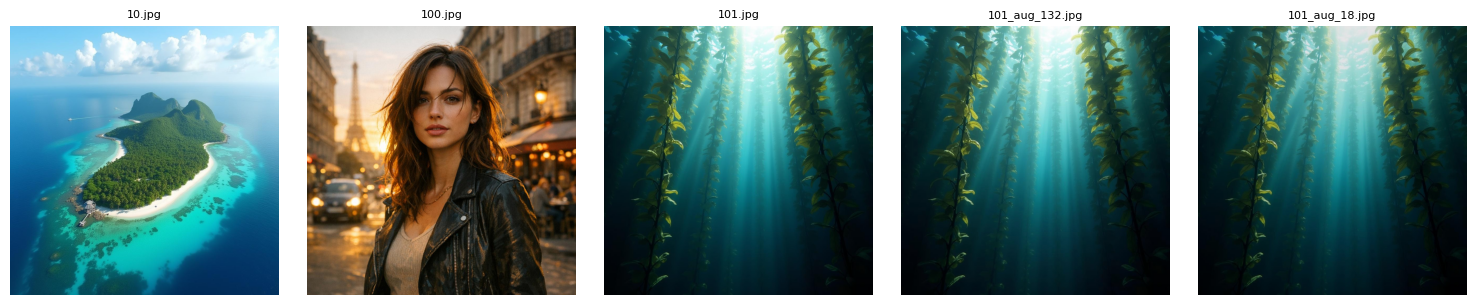

In [24]:
import matplotlib.pyplot as plt

def show_sample_images(base_dir, cls, n=5):
    cls_dir = Path(base_dir) / cls
    images = get_image_files(cls_dir)[:n]

    plt.figure(figsize=(15, 3))
    for i, img_path in enumerate(images):
        img = Image.open(img_path)
        plt.subplot(1, n, i + 1)
        plt.imshow(img)
        plt.title(img_path.name[:18], fontsize=8)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

for cls in CLASSES:
    show_sample_images(BALANCED_TRAIN_DIR, cls, n=5)